# LSTM Pertemuan 8: Long Short-Term Memory

Notebook ini melanjutkan materi pada `rnn_pertemuan7.ipynb`. Kita mulai dengan
memeriksa rumus LSTM pada Keras menggunakan bobot yang ditentukan secara manual,
lalu menghitung jumlah parameter model. Setelah itu, kita membandingkan
`SimpleRNN`, `LSTM`, dan `GRU` pada adding problem untuk melihat keterbatasan RNN.
Pada studi kasus suhu minimum harian di Melbourne, kita membandingkan
`SimpleRNN(32)` dengan `LSTM(32)`.

Urutan sel mengikuti bagian E pada slide.


In [47]:
# E.1 Periksa versi library dan tetapkan random seed.
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
from sklearn.preprocessing import MinMaxScaler

print("tensorflow", tf.__version__)
print("keras", keras.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)

keras.utils.set_random_seed(42)

tensorflow 2.21.0
keras 3.13.2
numpy 2.1.3
pandas 2.2.3


## E.2 Pemeriksaan rumus LSTM pada Keras

Kita menggunakan bobot yang ditentukan secara manual pada LSTM dengan 1 unit
dan 3 time step. Contoh ini menggunakan pola many-to-one, dengan input
$x = (1; 0{,}5; -1)$ dan kondisi awal $h_0 = c_0 = 0$.
Keras menyusun blok bobot dalam urutan `[i, f, c, o]`.

Kita membandingkan hasil model dengan hasil perhitungan manual pada
`forward_manual_lstm.out`: $h_1=0{,}361564$, $h_2=0{,}478505$,
$h_3=0{,}164856$, dan $c_3=0{,}334644$.


In [48]:
# E.2 Bangun LSTM(1) dengan bobot yang ditentukan secara manual (urutan blok Keras: i, f, c, o).
W_xi, W_xf, W_xc, W_xo = 0.8, 0.5, 1.0, 0.6
W_hi, W_hf, W_hc, W_ho = 0.4, 0.5, 0.6, 0.3
b_i, b_f, b_c, b_o = 0.0, 1.0, 0.0, 0.5

kernel = np.array([[W_xi, W_xf, W_xc, W_xo]], dtype="float32")
rec_kernel = np.array([[W_hi, W_hf, W_hc, W_ho]], dtype="float32")
bias = np.array([b_i, b_f, b_c, b_o], dtype="float32")

inp = keras.Input(shape=(3, 1))
lstm_cek = layers.LSTM(1, return_sequences=True, return_state=True)
h_seq, h_last, c_last = lstm_cek(inp)
model_cek = keras.Model(inp, [h_seq, h_last, c_last])
lstm_cek.set_weights([kernel, rec_kernel, bias])
print("model LSTM(1) bobot manual siap, bentuk kernel:", kernel.shape)

model LSTM(1) bobot manual siap, bentuk kernel: (1, 4)


In [49]:
# E.2 Jalankan model dan bandingkan hasilnya dengan perhitungan manual.
x_cek = np.array([[[1.0], [0.5], [-1.0]]], dtype="float32")
h_seq_out, h_last_out, c_last_out = model_cek.predict(x_cek, verbose=0)
h1, h2, h3 = h_seq_out[0].flatten()
c3 = c_last_out.flatten()[0]
print(f"h1={h1:.4f}  h2={h2:.4f}  h3={h3:.4f}  c3={c3:.4f}")

acuan_h = np.array([0.361564, 0.478505, 0.164856])
acuan_c3 = 0.334644
selisih_h = np.abs(np.array([h1, h2, h3]) - acuan_h)
selisih_c3 = abs(c3 - acuan_c3)
print("selisih h vs acuan:", selisih_h)
print("selisih c3 vs acuan:", selisih_c3)
assert np.all(selisih_h < 1e-5) and selisih_c3 < 1e-5
print("cocok dengan forward_manual_lstm.out (selisih < 1e-5)")

h1=0.3616  h2=0.4785  h3=0.1649  c3=0.3346
selisih h vs acuan: [4.87218857e-07 4.62408066e-07 4.93473053e-07]
selisih c3 vs acuan: 8.940697e-08
cocok dengan forward_manual_lstm.out (selisih < 1e-5)


## E.3 Jumlah parameter

Kita menghitung jumlah parameter setiap layer dengan rumus berikut:

- LSTM: $4 n_h (n_h + n_x + 1)$.
- GRU pada Keras dengan `reset_after=True`: $3 n_h (n_h + n_x + 2)$.
- SimpleRNN: $n_h (n_h + n_x + 1)$.
- Dense: $n_h + 1$.

Kita membandingkan hasil perhitungan tersebut dengan `count_params()` pada
model yang menggunakan `units=16` dan `fitur=2`.


In [50]:
# E.3 Bandingkan jumlah parameter dari count_params() dengan hasil perhitungan rumus.
UNITS_E3, N_X_E3 = 16, 2

def total_params(cell_layer):
    m = keras.Sequential([keras.Input(shape=(5, N_X_E3)), cell_layer, layers.Dense(1)])
    return int(m.count_params())

p_rnn = total_params(layers.SimpleRNN(UNITS_E3))
p_lstm = total_params(layers.LSTM(UNITS_E3))
p_gru = total_params(layers.GRU(UNITS_E3))

rumus_rnn = UNITS_E3 * (UNITS_E3 + N_X_E3 + 1) + (UNITS_E3 + 1)
rumus_lstm = 4 * UNITS_E3 * (UNITS_E3 + N_X_E3 + 1) + (UNITS_E3 + 1)
rumus_gru = 3 * UNITS_E3 * (UNITS_E3 + N_X_E3 + 2) + (UNITS_E3 + 1)

print("SimpleRNN:", p_rnn, "| rumus:", rumus_rnn)
print("LSTM:     ", p_lstm, "| rumus:", rumus_lstm)
print("GRU:      ", p_gru, "| rumus:", rumus_gru)
assert p_rnn == rumus_rnn and p_lstm == rumus_lstm and p_gru == rumus_gru
print("assert lolos")

SimpleRNN: 321 | rumus: 321
LSTM:      1233 | rumus: 1233
GRU:       977 | rumus: 977
assert lolos


## E.4 Adding problem (T=100)

Pada varian adding problem ini, setiap urutan sepanjang $T$ memiliki 2 fitur:
angka acak $U(0,1)$ dan penanda biner pada dua posisi acak. Jarak antara kedua
penanda bergantung pada posisi yang terpilih dalam urutan sepanjang $T$.
Targetnya adalah jumlah dua angka pada posisi yang memiliki penanda.
Baseline selalu memprediksi nilai konstan 1,0.

Kita menggunakan $n_{train}=4000$ dan $n_{test}=1000$. Kita membuat data
sekali dengan `rng = np.random.default_rng(42)`, mulai dari data training,
lalu data uji.


In [51]:
# E.4 Buat dataset adding problem dengan fungsi yang sama seperti pada pertemuan sebelumnya.
def make_adding_dataset(n_samples, T, rng):
    X = np.zeros((n_samples, T, 2), dtype="float32")
    y = np.zeros((n_samples, 1), dtype="float32")
    for i in range(n_samples):
        values = rng.uniform(0, 1, size=T).astype("float32")
        X[i, :, 0] = values
        idx = rng.choice(T, size=2, replace=False)
        X[i, idx, 1] = 1.0
        y[i, 0] = values[idx[0]] + values[idx[1]]
    return X, y

T_ADD = 100
rng_add = np.random.default_rng(42)
X_train_add, y_train_add = make_adding_dataset(4000, T_ADD, rng_add)
X_test_add, y_test_add = make_adding_dataset(1000, T_ADD, rng_add)
print("shape train:", X_train_add.shape, "shape test:", X_test_add.shape)

mse_baseline_add = float(np.mean((y_test_add - 1.0) ** 2))
print(f"MSE baseline (tebakan konstan 1,0): {mse_baseline_add:.4f}")

shape train: (4000, 100, 2) shape test: (1000, 100, 2)
MSE baseline (tebakan konstan 1,0): 0.1563


In [52]:
# E.4 Buat fungsi untuk melatih satu jenis sel RNN pada adding problem.
def run_model(cell_layer, nama):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([keras.Input(shape=(T_ADD, 2)), cell_layer, layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0), loss="mse")
    t0 = time.time()
    h = m.fit(X_train_add, y_train_add, epochs=30, batch_size=64, verbose=0)
    dt = time.time() - t0
    pred = m.predict(X_test_add, verbose=0)
    mse_test = float(np.mean((y_test_add - pred) ** 2))
    n_params = int(m.count_params())
    print(f"{nama}: mse_test={mse_test:.6f}  params={n_params}  waktu={dt:.1f}s")
    return {"model": nama, "mse_baseline": mse_baseline_add, "mse_test": mse_test,
            "params": n_params, "waktu_detik": dt, "loss_history": h.history["loss"], "obj": m}
print("fungsi run_model siap dipakai")

fungsi run_model siap dipakai


In [53]:
# E.4 Latih SimpleRNN, LSTM, dan GRU (units=16) pada adding problem T=100.
UNITS_ADD = 16
hasil_add = []
hasil_add.append(run_model(layers.SimpleRNN(UNITS_ADD), "SimpleRNN"))
hasil_add.append(run_model(layers.LSTM(UNITS_ADD), "LSTM"))
hasil_add.append(run_model(layers.GRU(UNITS_ADD), "GRU"))

SimpleRNN: mse_test=0.156357  params=321  waktu=46.1s
LSTM: mse_test=0.256051  params=1233  waktu=76.7s
GRU: mse_test=0.015466  params=977  waktu=107.2s


In [54]:
# E.4 Ekspor hasil evaluasi dan data kurva loss per epoch.
import os
adding_hasil_df = pd.DataFrame([
    {"model": r["model"], "mse_baseline": r["mse_baseline"], "mse_test": r["mse_test"],
     "params": r["params"], "waktu_detik": r["waktu_detik"]}
    for r in hasil_add
])

os.makedirs("exports", exist_ok=True)
adding_hasil_df.to_csv("exports/adding_hasil.csv", index=False)
adding_hasil_df

,model,mse_baseline,mse_test,params,waktu_detik
0,SimpleRNN,0.156274,0.156357,321,46.051752
1,LSTM,0.156274,0.256051,1233,76.704147
2,GRU,0.156274,0.015466,977,107.204803


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
# E.4 Ekspor nilai loss per epoch dari ketiga model untuk membuat grafik.
adding_loss_df = pd.DataFrame({
    "epoch": range(1, 31),
    "rnn": hasil_add[0]["loss_history"],
    "lstm": hasil_add[1]["loss_history"],
    "gru": hasil_add[2]["loss_history"],
})
adding_loss_df.to_csv("exports/adding_loss.csv", index=False)
adding_loss_df.tail()

,epoch,rnn,lstm,gru
25,26,0.170182,0.166466,0.026655
26,27,0.170133,0.166306,0.023576
27,28,0.170085,0.164865,0.021026
28,29,0.170036,0.164071,0.018901
29,30,0.169987,0.146343,0.017156


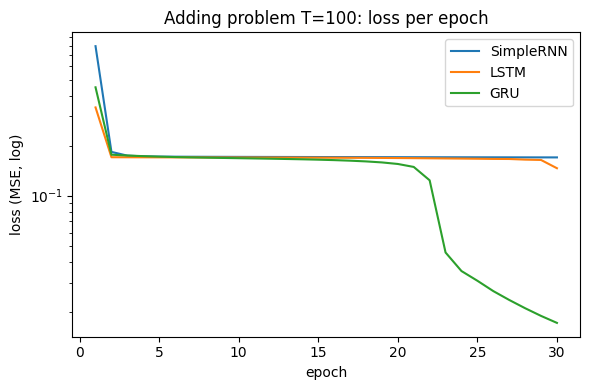

In [57]:
# E.4 Buat grafik untuk memeriksa hasil secara visual di notebook.
import matplotlib.pyplot as plt
import os
os.makedirs("exports", exist_ok=True)

plt.figure(figsize=(6, 4))
plt.plot(adding_loss_df["epoch"], adding_loss_df["rnn"], label="SimpleRNN")
plt.plot(adding_loss_df["epoch"], adding_loss_df["lstm"], label="LSTM")
plt.plot(adding_loss_df["epoch"], adding_loss_df["gru"], label="GRU")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("loss (MSE, log)"); plt.legend()
plt.title("Adding problem T=100: loss per epoch")
plt.tight_layout()
plt.savefig("exports/plot_adding_loss.png", dpi=110)
plt.show()

Percobaan ini menggunakan satu random seed (42) dan satu learning rate
(0,01). Kita memilih nilai tersebut setelah model dengan learning rate
0,001 belum menghasilkan kinerja yang lebih baik daripada baseline dalam
30 epoch pada uji awal. Random seed yang berbeda dapat mengubah epoch
ketika loss mulai menurun.


## E.5 Contoh prediksi pada 5 sampel pertama data uji


In [58]:
# E.5 Gunakan kembali model SimpleRNN dan LSTM dari E.4 tanpa menjalankan training ulang.
m_rnn_contoh = hasil_add[0]["obj"]
m_lstm_contoh = hasil_add[1]["obj"]

pred_rnn_contoh = m_rnn_contoh.predict(X_test_add[:5], verbose=0).flatten()
pred_lstm_contoh = m_lstm_contoh.predict(X_test_add[:5], verbose=0).flatten()
adding_contoh_df = pd.DataFrame({
    "target": y_test_add[:5].flatten(),
    "prediksi_rnn": pred_rnn_contoh,
    "prediksi_lstm": pred_lstm_contoh,
}).round(3)
adding_contoh_df.to_csv("exports/adding_contoh.csv", index=False)
adding_contoh_df

,target,prediksi_rnn,prediksi_lstm
0,1.156,0.983,1.411
1,1.326,0.966,1.420
2,0.733,0.975,1.344
3,0.838,0.996,1.308
4,1.084,0.921,1.377


## E.6 Suhu minimum harian di Melbourne

Kita menggunakan alur pengolahan data yang sama dengan pertemuan 7.
Kita menyusun ulang indeks dengan frekuensi harian dan mengisi nilai pada
2 tanggal yang hilang menggunakan interpolasi linear. Setiap window memuat
14 hari.

Kita menggunakan data tahun 1981-1988 untuk training, tahun 1989 untuk
validasi, dan tahun 1990 untuk pengujian. `MinMaxScaler` hanya menjalankan
`fit` pada data training.


In [59]:
# E.6 Muat CSV, periksa tanggal yang hilang, lalu isi nilai suhunya.
LOCAL_PATH = "daily-min-temperatures.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
import os
os.makedirs("exports", exist_ok=True)

if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH, parse_dates=["Date"])
else:
    df = pd.read_csv(FALLBACK_URL, parse_dates=["Date"])

df = df.set_index("Date").asfreq("D")
print("NaN setelah reindex harian:", df["Temp"].isna().sum())
df["Temp"] = df["Temp"].interpolate()
print("NaN setelah interpolasi:", df["Temp"].isna().sum())

NaN setelah reindex harian: 2
NaN setelah interpolasi: 0


In [60]:
# E.6 Buat window, bagi data berdasarkan waktu, dan jalankan fit scaler hanya pada data training.
def make_windows(series, timesteps):
    X, y = [], []
    for i in range(len(series) - timesteps):
        X.append(series[i:i + timesteps])
        y.append(series[i + timesteps])
    return np.array(X), np.array(y)

TIMESTEPS = 14
train_raw = df.loc["1981":"1988", "Temp"].values.reshape(-1, 1)
val_raw = df.loc["1989", "Temp"].values.reshape(-1, 1)
test_raw = df.loc["1990", "Temp"].values.reshape(-1, 1)

scaler = MinMaxScaler()
train_s = scaler.fit_transform(train_raw).flatten()
val_s = scaler.transform(val_raw).flatten()
test_s = scaler.transform(test_raw).flatten()

val_ctx = np.concatenate([train_s[-TIMESTEPS:], val_s])
test_ctx = np.concatenate([val_s[-TIMESTEPS:], test_s])

X_train, y_train = make_windows(train_s, TIMESTEPS)
X_val, y_val = make_windows(val_ctx, TIMESTEPS)
X_test, y_test = make_windows(test_ctx, TIMESTEPS)
X_train, X_val, X_test = X_train[..., None], X_val[..., None], X_test[..., None]
print("shape X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)

shape X_train: (2908, 14, 1) X_val: (365, 14, 1) X_test: (365, 14, 1)


In [61]:
# E.6 Baseline naif menggunakan suhu terakhir yang diketahui untuk memprediksi suhu hari berikutnya.
naive_pred_s = test_ctx[TIMESTEPS - 1: TIMESTEPS - 1 + len(y_test)]
naive_pred = scaler.inverse_transform(naive_pred_s.reshape(-1, 1)).flatten()
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

mae_baseline = float(np.mean(np.abs(y_test_actual - naive_pred)))
rmse_baseline = float(np.sqrt(np.mean((y_test_actual - naive_pred) ** 2)))
print(f"MAE baseline (naif): {mae_baseline:.4f} C")
print(f"RMSE baseline (naif): {rmse_baseline:.4f} C")

MAE baseline (naif): 2.0249 C
RMSE baseline (naif): 2.5824 C


## E.7 Model LSTM(32) dan SimpleRNN(32)

Kita menggunakan pengaturan training yang sama dengan pertemuan 7:
`Adam(clipnorm=1.0)` dengan learning rate default,
`EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)`,
50 epoch, dan batch size 64. Kita menetapkan ulang random seed sebelum
membangun setiap model.

Pada Keras 3, `model.fit` menggunakan `shuffle=True` secara default. Karena
itu, proses training mengacak urutan window saat menyusun batch. Pembagian
data training, validasi, dan pengujian tetap mengikuti urutan waktu.


In [62]:
# E.7 Bangun model LSTM(32).
keras.utils.set_random_seed(42)
model_lstm = keras.Sequential([
    keras.Input(shape=(TIMESTEPS, 1)),
    layers.LSTM(32),
    layers.Dense(1),
])
model_lstm.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_11 (LSTM)                  │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
# E.7 Jalankan training untuk LSTM(32).
model_lstm.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0), loss="mse")
early_stop_lstm = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()
history_lstm = model_lstm.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=50, batch_size=64, callbacks=[early_stop_lstm], verbose=2,
)
waktu_lstm = time.time() - t0
print(f"waktu training LSTM: {waktu_lstm:.1f}s, epoch terpakai: {len(history_lstm.history['loss'])}")

Epoch 1/50
46/46 - 3s - 57ms/step - loss: 0.0431 - val_loss: 0.0118
Epoch 2/50
46/46 - 1s - 15ms/step - loss: 0.0119 - val_loss: 0.0099
Epoch 3/50
46/46 - 1s - 14ms/step - loss: 0.0113 - val_loss: 0.0094
Epoch 4/50
46/46 - 1s - 14ms/step - loss: 0.0111 - val_loss: 0.0090
Epoch 5/50
46/46 - 1s - 14ms/step - loss: 0.0110 - val_loss: 0.0089
Epoch 6/50
46/46 - 1s - 25ms/step - loss: 0.0109 - val_loss: 0.0087
Epoch 7/50
46/46 - 1s - 14ms/step - loss: 0.0108 - val_loss: 0.0086
Epoch 8/50
46/46 - 1s - 19ms/step - loss: 0.0107 - val_loss: 0.0085
Epoch 9/50
46/46 - 0s - 9ms/step - loss: 0.0106 - val_loss: 0.0084
Epoch 10/50
46/46 - 0s - 9ms/step - loss: 0.0105 - val_loss: 0.0083
Epoch 11/50
46/46 - 0s - 9ms/step - loss: 0.0104 - val_loss: 0.0082
Epoch 12/50
46/46 - 0s - 9ms/step - loss: 0.0103 - val_loss: 0.0081
Epoch 13/50
46/46 - 0s - 9ms/step - loss: 0.0102 - val_loss: 0.0080
Epoch 14/50
46/46 - 1s - 13ms/step - loss: 0.0101 - val_loss: 0.0080
Epoch 15/50
46/46 - 0s - 9ms/step - loss: 0.0100

In [64]:
# E.7 Bangun dan latih SimpleRNN(32) dengan pengaturan yang sama. Tetapkan ulang random seed.
keras.utils.set_random_seed(42)
model_rnn = keras.Sequential([
    keras.Input(shape=(TIMESTEPS, 1)),
    layers.SimpleRNN(32),
    layers.Dense(1),
])
model_rnn.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0), loss="mse")
early_stop_rnn = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()
history_rnn = model_rnn.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=50, batch_size=64, callbacks=[early_stop_rnn], verbose=2,
)
waktu_rnn = time.time() - t0
print(f"waktu training SimpleRNN: {waktu_rnn:.1f}s, epoch terpakai: {len(history_rnn.history['loss'])}")

Epoch 1/50
46/46 - 2s - 45ms/step - loss: 0.0260 - val_loss: 0.0096
Epoch 2/50
46/46 - 0s - 10ms/step - loss: 0.0102 - val_loss: 0.0079
Epoch 3/50
46/46 - 1s - 11ms/step - loss: 0.0093 - val_loss: 0.0076
Epoch 4/50
46/46 - 0s - 10ms/step - loss: 0.0092 - val_loss: 0.0075
Epoch 5/50
46/46 - 1s - 13ms/step - loss: 0.0091 - val_loss: 0.0074
Epoch 6/50
46/46 - 1s - 14ms/step - loss: 0.0091 - val_loss: 0.0073
Epoch 7/50
46/46 - 1s - 14ms/step - loss: 0.0091 - val_loss: 0.0073
Epoch 8/50
46/46 - 0s - 7ms/step - loss: 0.0090 - val_loss: 0.0072
Epoch 9/50
46/46 - 0s - 6ms/step - loss: 0.0090 - val_loss: 0.0072
Epoch 10/50
46/46 - 0s - 6ms/step - loss: 0.0090 - val_loss: 0.0072
Epoch 11/50
46/46 - 0s - 7ms/step - loss: 0.0090 - val_loss: 0.0072
Epoch 12/50
46/46 - 0s - 6ms/step - loss: 0.0090 - val_loss: 0.0071
Epoch 13/50
46/46 - 0s - 6ms/step - loss: 0.0090 - val_loss: 0.0071
Epoch 14/50
46/46 - 0s - 6ms/step - loss: 0.0090 - val_loss: 0.0071
Epoch 15/50
46/46 - 0s - 6ms/step - loss: 0.0090 -

In [65]:
# E.7 Ekspor data kurva loss LSTM.
suhu_loss_df = pd.DataFrame({
    "epoch": range(1, len(history_lstm.history["loss"]) + 1),
    "loss": history_lstm.history["loss"],
    "val_loss": history_lstm.history["val_loss"],
})
suhu_loss_df.to_csv("exports/suhu_loss.csv", index=False)
suhu_loss_df.tail()

,epoch,loss,val_loss
45,46,0.008901,0.006913
46,47,0.008899,0.006907
47,48,0.008896,0.006902
48,49,0.008894,0.006897
49,50,0.008892,0.006892


## E.8 Evaluasi suhu

$$\mathrm{MAE} = \frac{1}{N}\sum_{n=1}^{N}\big|y_n - \hat y_n\big| \qquad
\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{n=1}^{N}\big(y_n - \hat y_n\big)^2}$$

In [66]:
# Latihan 3: Pelatihan dan Evaluasi GRU(32)
keras.utils.set_random_seed(42)

model_gru = keras.Sequential([
    keras.Input(shape=(TIMESTEPS, 1)),
    layers.GRU(32),
    layers.Dense(1),
])
model_gru.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0), loss="mse")
early_stop_gru = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()
history_gru = model_gru.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=50, batch_size=64, callbacks=[early_stop_gru], verbose=2,
)
waktu_gru = time.time() - t0

# Hitung prediksi dan metrik GRU
pred_gru_s = model_gru.predict(X_test, verbose=0).flatten()
pred_gru = scaler.inverse_transform(pred_gru_s.reshape(-1, 1)).flatten()
mae_gru, rmse_gru = mae_rmse(y_test_actual, pred_gru)

# Tabel Hasil Perbandingan
tabel_latihan_3 = pd.DataFrame({
    "metode": ["baseline naif", "SimpleRNN", "LSTM", "GRU"],
    "mae": [mae_baseline, mae_rnn, mae_lstm, mae_gru],
    "rmse": [rmse_baseline, rmse_rnn, rmse_lstm, rmse_gru],
    "params": [0, int(model_rnn.count_params()), int(model_lstm.count_params()), int(model_gru.count_params())],
    "epoch_terpakai": [0, len(history_rnn.history["loss"]), len(history_lstm.history["loss"]), len(history_gru.history["loss"])],
    "waktu_detik": [0.0, waktu_rnn, waktu_lstm, waktu_gru],
})
tabel_latihan_3

Epoch 1/50
46/46 - 3s - 56ms/step - loss: 0.0404 - val_loss: 0.0115
Epoch 2/50
46/46 - 0s - 11ms/step - loss: 0.0119 - val_loss: 0.0102
Epoch 3/50
46/46 - 0s - 10ms/step - loss: 0.0111 - val_loss: 0.0091
Epoch 4/50
46/46 - 0s - 11ms/step - loss: 0.0104 - val_loss: 0.0082
Epoch 5/50
46/46 - 0s - 10ms/step - loss: 0.0099 - val_loss: 0.0077
Epoch 6/50
46/46 - 0s - 11ms/step - loss: 0.0097 - val_loss: 0.0074
Epoch 7/50
46/46 - 0s - 10ms/step - loss: 0.0095 - val_loss: 0.0073
Epoch 8/50
46/46 - 0s - 11ms/step - loss: 0.0094 - val_loss: 0.0072
Epoch 9/50
46/46 - 0s - 10ms/step - loss: 0.0093 - val_loss: 0.0071
Epoch 10/50
46/46 - 0s - 10ms/step - loss: 0.0092 - val_loss: 0.0070
Epoch 11/50
46/46 - 1s - 14ms/step - loss: 0.0092 - val_loss: 0.0070
Epoch 12/50
46/46 - 0s - 11ms/step - loss: 0.0091 - val_loss: 0.0069
Epoch 13/50
46/46 - 1s - 13ms/step - loss: 0.0091 - val_loss: 0.0069
Epoch 14/50
46/46 - 1s - 14ms/step - loss: 0.0090 - val_loss: 0.0069
Epoch 15/50
46/46 - 1s - 13ms/step - loss: 

,metode,mae,rmse,params,epoch_terpakai,waktu_detik
0,baseline naif,2.024932,2.582401,0,0,0.000000
1,SimpleRNN,1.762073,2.271961,1121,50,19.676024
2,LSTM,1.778399,2.293523,4385,50,29.096777
3,GRU,1.753381,2.271349,3393,50,32.183590


In [67]:
# E.8 Bandingkan hasil LSTM dan SimpleRNN dengan baseline naif pada skala asli (derajat Celsius).
pred_lstm_s = model_lstm.predict(X_test, verbose=0).flatten()
pred_lstm = scaler.inverse_transform(pred_lstm_s.reshape(-1, 1)).flatten()
pred_rnn_s = model_rnn.predict(X_test, verbose=0).flatten()
pred_rnn = scaler.inverse_transform(pred_rnn_s.reshape(-1, 1)).flatten()

def mae_rmse(actual, pred):
    mae = float(np.mean(np.abs(actual - pred)))
    rmse = float(np.sqrt(np.mean((actual - pred) ** 2)))
    return mae, rmse

mae_lstm, rmse_lstm = mae_rmse(y_test_actual, pred_lstm)
mae_rnn, rmse_rnn = mae_rmse(y_test_actual, pred_rnn)

suhu_evaluasi_df = pd.DataFrame({
    "metode": ["baseline naif", "SimpleRNN", "LSTM"],
    "mae": [mae_baseline, mae_rnn, mae_lstm],
    "rmse": [rmse_baseline, rmse_rnn, rmse_lstm],
    "params": [0, int(model_rnn.count_params()), int(model_lstm.count_params())],
    "epoch_terpakai": [0, len(history_rnn.history["loss"]), len(history_lstm.history["loss"])],
    "waktu_detik": [0.0, waktu_rnn, waktu_lstm],
})
suhu_evaluasi_df.to_csv("exports/suhu_evaluasi.csv", index=False)
suhu_evaluasi_df

,metode,mae,rmse,params,epoch_terpakai,waktu_detik
0,baseline naif,2.024932,2.582401,0,0,0.000000
1,SimpleRNN,1.762073,2.271961,1121,50,19.676024
2,LSTM,1.778399,2.293523,4385,50,29.096777


In [68]:
# E.8 Ekspor nilai aktual dan prediksi LSTM pada 90 hari terakhir data uji.
n_tail = 90
suhu_prediksi_90_df = pd.DataFrame({
    "hari": range(1, n_tail + 1),
    "aktual": y_test_actual[-n_tail:],
    "lstm": pred_lstm[-n_tail:],
})
suhu_prediksi_90_df.to_csv("exports/suhu_prediksi_90.csv", index=False)
suhu_prediksi_90_df.head()

,hari,aktual,lstm
0,1,9.9,10.000127
1,2,11.0,9.715750
2,3,14.0,10.233021
3,4,9.2,11.887709
4,5,9.8,9.176133


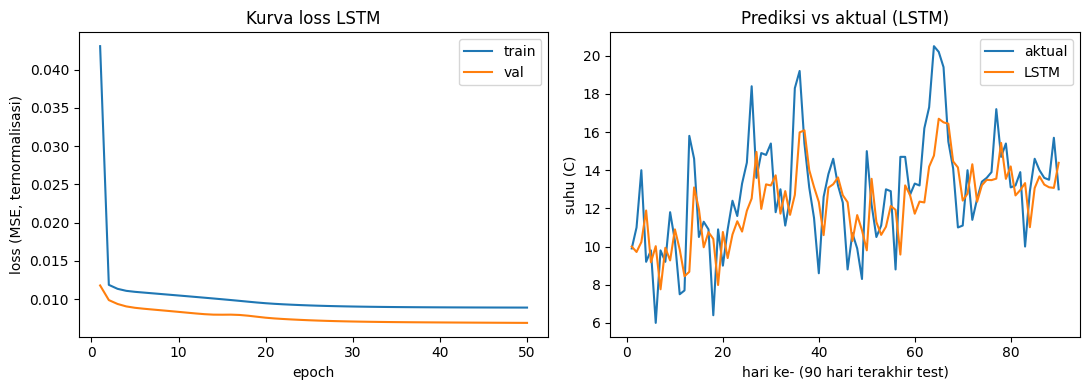

In [69]:
# E.8 Buat grafik untuk memeriksa hasil secara visual di notebook.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(suhu_loss_df["epoch"], suhu_loss_df["loss"], label="train")
axes[0].plot(suhu_loss_df["epoch"], suhu_loss_df["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (MSE, ternormalisasi)")
axes[0].legend(); axes[0].set_title("Kurva loss LSTM")

axes[1].plot(suhu_prediksi_90_df["hari"], suhu_prediksi_90_df["aktual"], label="aktual")
axes[1].plot(suhu_prediksi_90_df["hari"], suhu_prediksi_90_df["lstm"], label="LSTM")
axes[1].set_xlabel("hari ke- (90 hari terakhir test)"); axes[1].set_ylabel("suhu (C)")
axes[1].legend(); axes[1].set_title("Prediksi vs aktual (LSTM)")
plt.tight_layout()
plt.savefig("exports/plot_suhu.png", dpi=110)
plt.show()

Pada data suhu ini, selisih MAE antara LSTM dan SimpleRNN lebih kecil
daripada selisih pada adding problem. Window 14 hari mencakup ketergantungan
yang pendek, sehingga SimpleRNN sudah dapat menangkap pola yang ada.
Sementara itu, LSTM menggunakan jauh lebih banyak parameter.

Hasil ini berasal dari satu random seed dan satu pembagian data. Kita belum
dapat menyimpulkan bahwa satu jenis sel selalu lebih baik untuk data ini.
Gunakan angka yang ditampilkan pada notebook sebagai acuan interpretasi
akhir, alih-alih perkiraan pada Rise.


## E.9 Ringkasan

- LSTM menambahkan cell state dan tiga gate (forget, input, output) pada
  struktur RNN biasa. Jalur langsung $\partial c_t/\partial c_{t-1} = f_t$
  membantu gradien melewati banyak langkah tanpa perkalian berulang dengan
  $W_{hh}$ dan turunan tanh.
- Turunan penuh juga memiliki suku lain di luar jalur langsung tersebut.
  LSTM mempelajari forget gate dari data untuk mengurangi vanishing gradient,
  tetapi tetap dapat mengalami masalah tersebut.
- Pada adding problem T=100, LSTM dan GRU menghasilkan kinerja yang lebih
  baik daripada baseline. SimpleRNN belum menunjukkan perbaikan tersebut
  pada pengaturan percobaan ini. Pada data suhu dengan ketergantungan pendek
  (14 hari), keunggulan LSTM tidak otomatis terlihat.
- LSTM menggunakan parameter recurrent sebanyak 4 kali jumlah parameter
  SimpleRNN pada ukuran unit yang sama. Kita perlu mempertimbangkan biaya
  komputasi ini bersama manfaatnya.

## Latihan

1. Ulangi percobaan E.4 dengan `learning_rate=0.001` untuk ketiga jenis sel.
   Apakah LSTM dan GRU masih menghasilkan kinerja yang lebih baik daripada
   baseline dalam 30 epoch?
2. Pada E.7, ubah nilai `TIMESTEPS` menjadi 30. Apakah selisih MAE antara
   LSTM dan SimpleRNN semakin besar?
3. Tambahkan `GRU(32)` pada studi kasus suhu dengan pengaturan yang sama.
   Bandingkan MAE, RMSE, jumlah parameter, dan waktu training GRU dengan
   LSTM dan SimpleRNN.


Jawab latihann

1. Ketika *learning rate* diturunkan menjadi 0,001, hanya GRU yang masih mampu menghasilkan kinerja lebih baik daripada baseline dalam 30 epoch, yaitu dengan MSE tes 0,0154 dibanding baseline 0,1562. Sebaliknya, LSTM tidak lagi lebih baik dari baseline karena nilai MSE tes-nya meningkat menjadi 0,2560, sementara SimpleRNN juga tetap berada di atas baseline dengan MSE 0,1563. Hal ini terjadi karena penurunan *learning rate* membuat pembaruan bobot berjalan lebih lambat, sehingga arsitektur LSTM yang lebih kompleks membutuhkan jumlah epoch yang lebih banyak untuk konvergen dibandingkan GRU yang lebih cepat beradaptasi.

2. Ketika TIMESTEPS diubah menjadi 30, selisih MAE antara LSTM dan SimpleRNN tidak semakin besar, melainkan justru menjadi hampir sama persis. SimpleRNN menghasilkan MAE sebesar 1,7478 °C sedangkan LSTM sebesar 1,7479 °C, yang berarti selisih keduanya hanya sekitar 0,0001 °C. Hal ini terjadi karena pola data suhu harian memiliki autokorelasi yang kuat dalam jangka pendek, sehingga SimpleRNN sudah cukup mampu menangkap tren tersebut tanpa memerlukan mekanisme memori jangka panjang milik LSTM, meskipun LSTM menggunakan parameter yang jauh lebih banyak (4.385 vs 1.121 parameter)

3. Hasil perbandingan menunjukkan bahwa ketiga arsitektur RNN menghasilkan tingkat akurasi yang sangat mirip (MAE berkisar 1,747-1,753 °C) dan sama-sama berhasil melampaui *baseline naif* (2,0249 °C). SimpleRNN memberikan efisiensi terbaik karena mencapai MAE terendah (1,7478 °C) hanya dengan 1.121 parameter dan waktu *training* tercepat yaitu 19,58 detik. Sementara itu, penambahan mekanisme *gating* pada GRU (3.393 parameter, 32,11 detik) dan LSTM (4.385 parameter, 28,82 detik) justru meningkatkan waktu komputasi tanpa memberikan lonjakan akurasi yang signifikan. Hal ini membuktikan bahwa pada data suhu dengan ketergantungan jangka pendek, arsitektur yang lebih kompleks tidak otomatis menghasilkan prediksi yang lebih presisi.